# Standalone positioning: from pseudoranges to a position

A pseudorange is a signal's travel time multiplied by the speed of light: the distance to
a satellite, offset by clock errors and stretched by delays along the path. A standalone
receiver turns several of them into its own position using only what the satellites
broadcast, their orbit and clock parameters and the coefficients of an ionosphere model.
It needs no base station and no correction service. In this notebook GPS L1 C/A
pseudoranges become a position and a receiver clock bias at every epoch, and RTKLIB solves
the same files as a check on the arithmetic.

If the receiver's clock were perfect and the signal crossed a vacuum, each pseudorange
would be the radius of a sphere centred on its satellite, and the receiver would sit where
the spheres meet. A receiver clock error changes every radius by the same amount, so the
solver estimates the clock as well. Write the receiver position as
$\mathbf{x}_r = (x, y, z)$, the position of satellite $s$ as $\mathbf{x}^s$, its
pseudorange as $P^s$, the receiver clock bias as $\mathrm{dt}_r$ in seconds and the speed
of light as $c$. Setting aside the satellite clock, the atmosphere and the Earth's rotation
for now,

$$P^s = \lVert \mathbf{x}^s - \mathbf{x}_r \rVert + c\,\mathrm{dt}_r .$$

There are exactly four unknowns: $x$, $y$, $z$ and the clock term $c\,\mathrm{dt}_r$, kept
in metres. Four satellites in a usable geometry determine them; more satellites let the
fit average down the measurement noise. The clock term is large: a receiver clock 1 µs off
adds about 300 m to every pseudorange. Section 4 puts back the terms set aside here.

The sections follow the computation: reading the observations (1), working out where each
satellite was and what its clock read (2), predicting the atmospheric delays (3), fitting
position and clock by weighted least squares (4), and comparing with RTKLIB (5).

The measurements are of the kind [notebook 01](01-signal-chain.ipynb) produces, but this
notebook reads an independent record that uses none of notebook 01's output files: the IGS
station USUD in Usuda, Japan, on 2021-12-26, observations every 30 s from 08:00 to 11:00
GPS time, 361 epochs. Three hours of a fixed station show the solution as the satellite
geometry changes, and the station's published coordinates give a reference position to
measure it against. The committed outputs come from these files. The first code cell
prints which data it found; [data paths](README.md#data-paths) describes the setup.

Synthetic data: without the station files the notebook generates an hour of epochs from the
package's six-satellite test constellation, with a drifting receiver clock. Those
pseudoranges contain the same atmospheric models the solver removes, plus 0.3 m of noise,
so they show the computation without the station's unmodelled errors. The IGS orbit and
RTKLIB comparisons are skipped.

The [glossary](../../docs/fundamentals/glossary.md) defines pseudorange, ephemeris, epoch
and ECEF; the [notation](README.md#notation) table lists the symbols and units used below.

In [1]:
import warnings

import hatanaka
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from support import (
    PVT_SPAN,
    PVT_WINDOW,
    USUD_MARKER,
    data_source,
    diagram_arrow,
    diagram_box,
    diagram_canvas,
    diagram_text,
    elapsed_minutes,
    enu,
    figure,
    figure_note,
    rnx2rtkp_single,
    scratch_dir,
    synthetic_pvt_epochs,
    time_note,
)

from pyrx.gpstime import GPS_EPOCH, gps_datetime
from pyrx.models import azimuth_elevation, geodetic, klobuchar, saastamoinen
from pyrx.orbits import satellite_clock, satellite_state, select_ephemeris
from pyrx.plots import BAR, BAR_DETECTED, HIGHLIGHT, INK, LINES, MUTED
from pyrx.pvt import IONO_DEFAULT, solve
from pyrx.rinex import read_rinex_header, read_rinex_nav, read_rinex_obs

out = scratch_dir("02-standalone-pvt")
src = data_source()
if src is not None:
    epochs = read_rinex_obs(src.usud_obs, PVT_WINDOW)
    ephs, iono = read_rinex_nav(src.usud_nav)
    # the reference position of the plots; the solver is never given it
    truth = USUD_MARKER
else:
    # pseudoranges from the package's own models, with 0.3 m of code noise added
    epochs, ephs, iono, truth = synthetic_pvt_epochs()
if src is None:
    iono_source = "RTKLIB's default set, also used to generate the observations"
elif iono is None or not any(iono.alpha + iono.beta):
    iono_source = "absent from the file, so the solver uses RTKLIB's default set"
else:
    iono_source = "broadcast coefficients from the navigation file"
print(f"{len(epochs)} epochs, {len(ephs)} ephemerides; ionosphere: {iono_source}")

running on the recordings named by PYRX_CAPTURES


361 epochs, 162 ephemerides; ionosphere: broadcast coefficients from the navigation file


## 1. Reading RINEX

RINEX is the text format receivers and station networks use to exchange measurements and
navigation messages. An observation file starts with a header describing the station and
the measurement types, then holds a block for each epoch (one measurement time) with a line
per satellite. A navigation file holds the broadcast ephemerides: each satellite's orbit
and clock parameters as the satellite transmitted them. For how a receiver forms these
measurements and writes them in this format, see [notebook 01](01-signal-chain.ipynb); here
the files come from the station.

The header printed below names each observation type with three characters. The first says
what was measured: C is code (the pseudorange, in metres), L carrier phase (cycles),
D Doppler (Hz) and S signal strength (here C/N0 in dB-Hz). The digit is the frequency band
and the last character the tracking mode, so C1C and L1C are the code and phase of the GPS
L1 C/A signal. In C1C the first C means code and the last C means the C/A code; neither is
the system letter C that marks BeiDou rows. C1W is another L1 code measurement, L5Q the
phase of the L5 Q component.

The letter at the start of each type list is the system: G for GPS, E Galileo, R GLONASS,
C BeiDou and J QZSS. The file carries far more than this example uses. `read_rinex_obs`
asks for GPS C1C, L1C, D1C and S1C only and keeps a satellite when its pseudorange is
present. USUD logs no D1C, so its Dopplers are `nan`; the synthetic builder leaves Doppler
as `nan` too and puts 0.0 in the unused carrier-phase field. Without four usable Dopplers
the solver returns no velocity or clock drift, so this notebook estimates position and
clock bias only.

The station file is Hatanaka-compressed and then gzipped; the cell expands both layers to
print the header. `RinexHeader` holds the fields the library extracts: marker name,
approximate position, antenna offset, antenna type and receiver type. `position` is
`APPROX POSITION XYZ` in metres, in Earth-centred, Earth-fixed coordinates (ECEF). The file
lists the antenna offset as height, east, north (H/E/N) and the library stores it as east,
north, up in `delta_enu`, so USUD's −0.035, 0, 0 becomes [0, 0, −0.035] m: the antenna
reference point sits 3.5 cm below the marker. The single-point solve here does not apply
that offset.

The reference position of the plots, `truth`, is `USUD_MARKER`, the marker coordinates from
the station's IGS site log, which equal the header's approximate position; on the synthetic
path it is the generating position. The offsets measured below cannot tell an error of the
fix from an error of the reference.

The last printed line counts the GPS satellites with a pseudorange at each epoch. The
solver uses fewer once it drops satellites without a usable broadcast record and those
below the elevation mask; section 4 plots both counts. On the synthetic path a table of the
first epoch's observations replaces the header.

Read more: [The measurements](../../docs/fundamentals/07-measurements.md).

In [2]:
if src is not None:
    # expand both compression layers so that the header can be read as text
    text = hatanaka.decompress(src.usud_obs).decode()
    header = text[: text.index("END OF HEADER")].splitlines()
    print("\n".join(header[:18]))
    print(read_rinex_header(src.usud_obs))
else:
    e = epochs[0]
    print(f"first epoch: week {e.week}, tow {e.tow:.1f} s")
    display(pd.DataFrame([vars(o) for o in e.obs]))
# satellites with a pseudorange; the solver's record checks and mask come later
observed = np.array([len(e.obs) for e in epochs])
counts = f"{observed.min()} to {observed.max()}" if observed.min() < observed.max() else observed[0]
print(f"{len(epochs)} epochs; {counts} GPS satellites observed per epoch")

     3.04           OBSERVATION DATA    M                   RINEX VERSION / TYPE
sbf2rin-13.8.0                          20211227 000219 UTC PGM / RUN BY / DATE
USUD                                                        MARKER NAME
21729S007                                                   MARKER NUMBER
GGN                 JPL                                     OBSERVER / AGENCY
3025546             SEPT POLARX5        5.4.0               REC # / TYPE / VERS
121                 AOAD/M_T        JPLA                    ANT # / TYPE
 -3855263.0361  3427432.5571  3741020.2929                  APPROX POSITION XYZ
        -0.0350       0.0000        0.0000                  ANTENNA: DELTA H/E/N
G   17 C1C L1C S1C C1W S1W C2W L2W S2W C2L L2L S2L C5Q L5Q  SYS / # / OBS TYPES
       S5Q C1L L1L S1L                                      SYS / # / OBS TYPES
E   15 C1C L1C S1C C6C L6C S6C C5Q L5Q S5Q C7Q L7Q S7Q C8Q  SYS / # / OBS TYPES
       L8Q S8Q                                              S

## 2. Satellite orbits

To turn a travel time into a position the solver needs to know where each satellite was
when it transmitted. The broadcast ephemeris describes an orbit close to an ellipse. Six
Kepler elements fix it at the orbit reference time `toe`: the semi-major axis $a$ (the
ellipse's size), the eccentricity $e$, the inclination $i_0$, the longitude of the
ascending node $\Omega_0$, the argument of perigee $\omega$ and the mean anomaly $M_0$, the
satellite's phase along the orbit. GPS transmits $\sqrt a$; the value near
5153.67 $\mathrm{m}^{1/2}$ decoded in notebook 01 squares to $a \approx 26\,560$ km, measured
from the Earth's centre rather than from the surface.

For a time $t$, let $t_k$ be $t$ minus `toe`, taken across the week boundary if need be.
The mean anomaly $M$ advances at a steady rate $n$, the Kepler mean motion plus a broadcast
correction $\Delta n$, but a satellite on an ellipse does not move at a steady rate. The
eccentric anomaly $E$ links the two through Kepler's equation, which the library solves by
Newton iteration starting from $E = M$ ($j$ counts the iterations):

$$M = M_0 + n\,t_k, \qquad E - e\sin E = M, \qquad
E_{j+1} = E_j - \frac{E_j - e\sin E_j - M}{1 - e\cos E_j}.$$

From $E$ the library gets the satellite's angle along the ellipse, then applies the
broadcast harmonic corrections (Cus and Cuc to the orbital angle, Crs and Crc to the
radius, Cis and Cic to the inclination), the broadcast rates of inclination and node, and
the Earth's rotation to express the position in ECEF. This is `satellite_state`, following
IS-GPS-200 Table 20-IV.

`select_ephemeris` picks the record whose `toe` is nearest the epoch, at most 2 h away in
either direction; on an exact tie it keeps the first record in the file. The satellite
clock has its own reference time, `toc`.

The sky plot evaluates every orbit 70 ms before the epoch, about 21 000 km of light travel,
which is close enough for a picture of the sky. The solver instead takes each satellite's
transmit time from its own pseudorange, corrects it by the satellite clock, and allows for
the Earth turning while the signal is in flight.

North is at the top of the plot and azimuth runs clockwise; the centre is overhead and the
rim is the horizon. Each track runs from an open circle (first sample) to a triangle (last
sample), with one sample every ten epochs. The dashed ring is the 15° elevation mask, so
any part of a track outside it is ignored by the solver. G04, G16 and G26 are drawn in
colour because the next figure compares their orbits with the IGS ones (on the synthetic
path only G04 exists).

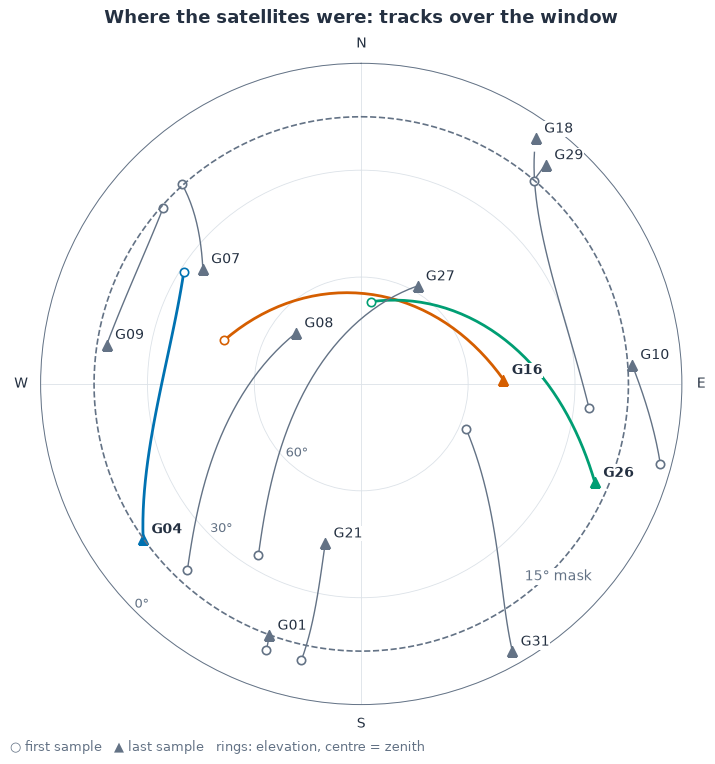

In [3]:
# one sample every tenth epoch keeps the tracks readable: (tow, azimuth, elevation)
sky = {}
for e in epochs[::10]:
    for o in e.obs:
        eph = select_ephemeris(ephs, o.prn, e.tow)
        if eph is None:
            continue
        # about 70 ms of light time; the solver uses each satellite's own pseudorange
        s = satellite_state(eph, e.tow - 0.07)
        az, el = azimuth_elevation(truth, s.position)
        sky.setdefault(o.prn, []).append((e.tow, az, np.degrees(el)))
compared = dict(zip((4, 16, 26), LINES))  # the satellites of the IGS orbit comparison
step = 10 * np.median(np.diff([e.tow for e in epochs]))

fig, ax = figure(figsize=(7, 7.4), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
for prn, samples in sorted(sky.items()):
    tow, az, el = np.array(samples).T
    r = 90 - el  # polar radius is the zenith angle: 0 overhead, 90 at the horizon
    color = compared.get(prn, MUTED)
    width = 2.0 if prn in compared else 1.0
    # break a track where the satellite left the view, and unwrap it across north
    breaks = np.flatnonzero(np.diff(tow) > 1.5 * step) + 1
    for seg_az, seg_r in zip(np.split(az, breaks), np.split(r, breaks)):
        ax.plot(np.unwrap(seg_az), seg_r, "-", color=color, linewidth=width)
    ax.plot(az[0], r[0], "o", mfc="white", mec=color, mew=1.2, ms=6)
    ax.plot(az[-1], r[-1], "^", color=color, ms=7)
    ax.annotate(f"G{prn:02d}", (az[-1], r[-1]), xytext=(6, 4), textcoords="offset points",
                fontsize=10, color=INK, fontweight="bold" if prn in compared else "normal",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.5})
# elevation 15 degrees is a polar radius of 75 degrees
ring = np.linspace(0, 2 * np.pi, 361)
ax.plot(ring, np.full(ring.size, 75), "--", color=MUTED, linewidth=1.2)
ax.annotate("15° mask", (np.radians(140), 75), xytext=(-6, 6), textcoords="offset points",
            fontsize=10, color=MUTED, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.set_rlim(0, 90)
ax.set_rticks([30, 60, 90], ["60°", "30°", "0°"], color=MUTED, fontsize=9)
ax.set_rlabel_position(225)
ax.set_xticks(np.radians([0, 90, 180, 270]), ["N", "E", "S", "W"])
ax.grid(True, color="#DCE2E8")
ax.set_title("Where the satellites were: tracks over the window", loc="center")
figure_note(fig, "○ first sample   ▲ last sample   rings: elevation, centre = zenith")
plt.show()

### Broadcast orbit and clock against the IGS final product

The International GNSS Service (IGS) computes satellite orbits and clocks after the fact
from a worldwide network of stations and publishes them in SP3 files. Its final product is
far more accurate than the broadcast ephemeris, so it serves as the reference here; the
fixes of section 4 still use only the broadcast ephemerides. The cell scans the whole day's
SP3 epochs for G04, G16 and G26 and keeps those with a broadcast record within 2 h, so the
coverage runs beyond the solution window, which is shaded.

Each panel plots the IGS value minus the broadcast value. The position difference is split
along three directions attached to the broadcast orbit. With the satellite position
$\mathbf{x}^s$ and its ECEF velocity $\mathbf{v}^s$, the radial (R), cross-track (C) and
along-track (A) unit vectors are

$$\mathbf{R} = \frac{\mathbf{x}^s}{\lVert\mathbf{x}^s\rVert}, \qquad
\mathbf{C} = \frac{\mathbf{x}^s \times \mathbf{v}^s}{\lVert\mathbf{x}^s \times \mathbf{v}^s\rVert},
\qquad \mathbf{A} = \mathbf{C} \times \mathbf{R}.$$

Radial points away from the Earth's centre, cross-track is normal to the plane of position
and velocity, and along-track completes the frame, close to the direction of motion.

The committed radial differences are all positive, between about +0.9 and +1.8 m: the
broadcast position lies inward of the IGS one. Part of that is a difference of reference
point. The IGS product gives the satellite's centre of mass, the broadcast orbit its
transmitting antenna, which sits on the Earth-facing side of the satellite. The rest is the
broadcast orbit's own error, which also shows in the along-track and cross-track panels.
A radial error passes almost fully into the range, because seen from the satellite the
receiver is never more than about 14° off the straight-down direction.

The clock panel compares the broadcast polynomial alone (`satellite_clock`) with the SP3
clock, so the relativistic term is absent on both sides. The differences lie between about
−2 and −6 ns (1 ns is 30 cm of range) and differ per satellite; G16 and G26 drift by one to
two nanoseconds over their tracks. The IGS clocks are tied to their own clock datum, which
can sit a few nanoseconds from the broadcast GPS time scale, and each broadcast clock has its
own error. The solver uses the full clock, relativistic term included, with the group delay
applied separately (section 4).

Synthetic data: there is no SP3 product for the generated orbits, so this comparison is
skipped.

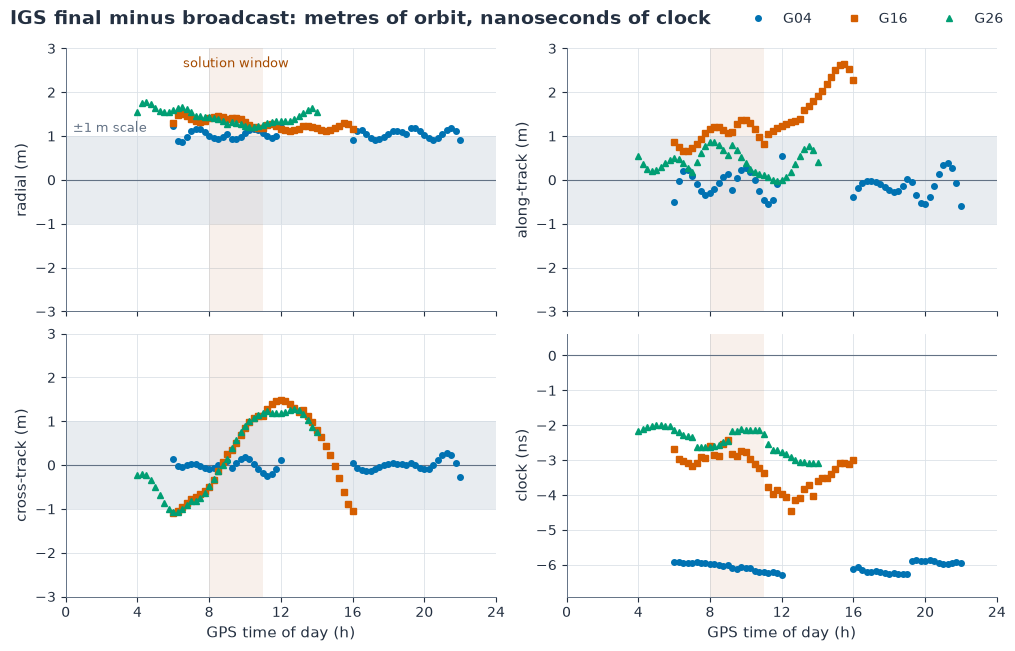

In [4]:
if src is None:
    print("Synthetic data: IGS comparison skipped (no SP3 product for the generated orbits).")
else:
    import georinex

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", FutureWarning)
        sp3 = georinex.load(src.sp3)
    marks = dict(zip(compared, "os^"))
    diffs = {}
    for prn in compared:
        rows = []
        # the whole day's SP3 epochs, independently of the solution window
        for t in sp3.time.values:
            tow = float(((t - np.datetime64(GPS_EPOCH)) / np.timedelta64(1, "s")) % 604800)
            eph = select_ephemeris(ephs, prn, tow)
            p = sp3.sel(sv=f"G{prn:02d}", time=t)
            # SP3 gives km and µs; its missing-clock value 999999.999999 µs is about 1 s
            pos, clk = p["position"].values * 1e3, float(p["clock"].values) * 1e-6
            if eph is None or not np.all(np.isfinite(pos)) or abs(clk) > 0.9:
                continue
            s = satellite_state(eph, tow)
            # radial, cross-track (normal to the orbit plane), along-track completes the frame
            radial = s.position / np.linalg.norm(s.position)
            cross = np.cross(s.position, s.velocity)
            cross /= np.linalg.norm(cross)
            along = np.cross(cross, radial)
            d = pos - s.position  # IGS minus broadcast
            # the clock polynomial alone, as SP3 clocks leave out the relativistic term
            dclk = (clk - satellite_clock(eph, tow)) * 1e9
            rows.append((tow / 3600 % 24, d @ radial, d @ along, d @ cross, dclk))
        diffs[prn] = np.array(rows)

    window = (epochs[0].tow / 3600 % 24, epochs[-1].tow / 3600 % 24)
    lim = max(3.0, 1.1 * max(np.abs(r[:, 1:4]).max() for r in diffs.values()))
    clocks = np.concatenate([r[:, 4] for r in diffs.values()])
    clim = (min(clocks.min(), 0.0), max(clocks.max(), 0.0))
    pad = 0.1 * (clim[1] - clim[0])
    names = ("radial (m)", "along-track (m)", "cross-track (m)", "clock (ns)")
    fig, axes = figure(2, 2, figsize=(10, 6.4), sharex=True)
    for j, (ax, name) in enumerate(zip(axes.flat, names), start=1):
        ax.axvspan(*window, color=HIGHLIGHT, alpha=0.08, linewidth=0)
        if j < 4:
            ax.axhspan(-1, 1, color=BAR, alpha=0.45, linewidth=0)
            ax.set_ylim(-lim, lim)
        else:
            ax.set_ylim(clim[0] - pad, clim[1] + pad)
        ax.axhline(0, color=MUTED, linewidth=0.8)
        for prn, color in compared.items():
            r = diffs[prn]
            ax.plot(r[:, 0], r[:, j], marks[prn], color=color, ms=4, linestyle="none",
                    label=f"G{prn:02d}")
        ax.set_ylabel(name)
        ax.set(xlim=(0, 24), xticks=range(0, 25, 4))
    for ax in axes[1]:
        ax.set_xlabel("GPS time of day (h)")
    axes[0, 0].annotate("±1 m scale", (0.01, 1), xycoords=axes[0, 0].get_yaxis_transform(),
                        xytext=(2, 3), textcoords="offset points", fontsize=9, color=MUTED)
    axes[0, 0].annotate("solution window", (sum(window) / 2, 0.97),
                        xycoords=axes[0, 0].get_xaxis_transform(), ha="center", va="top",
                        fontsize=9, color=HIGHLIGHT)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper right", ncols=3)
    fig.suptitle("IGS final minus broadcast: metres of orbit, nanoseconds of clock",
                 x=0.0, ha="left")
    plt.show()

## 3. The atmosphere

On its way down the signal crosses the ionosphere and the troposphere, and both delay it,
which lengthens the pseudorange. The solver predicts the two delays in metres, the
ionospheric delay $I$ with the Klobuchar model and the tropospheric delay $T$ with the
Saastamoinen model, and adds them to its range model before it fits position and clock.

Klobuchar predicts the GPS L1 code delay from eight coefficients broadcast in the
navigation message, the receiver's latitude and longitude, the satellite's azimuth and
elevation, and the time of day. It treats the ionosphere as a thin shell whose delay follows
a daily cycle. When the file has no usable coefficients the solver uses RTKLIB's default
set, and the synthetic observations are generated with that same set. The longer slant path
towards the horizon enters through an elevation factor: for elevation $\varepsilon$ in
radians,

$$I = c\,F(\varepsilon)\,\tau, \qquad F(\varepsilon) = 1 + 16\,(0.53 - \varepsilon/\pi)^3,$$

where $\tau$ is the model's vertical delay in seconds, set by the coefficients, the point
where the ray pierces the shell and the local time there. $F$ is 1.0 overhead and 2.4 at
15°. Different satellites look through different parts of the shell, so their ionospheric
delays do not fall on one curve of elevation.

Saastamoinen estimates the delay of the dry air and of the water vapour from the receiver's
latitude and height and a standard atmosphere, with relative humidity 0.7. In this
implementation the slant delay is the zenith delay $T_z$ divided by the sine of the
elevation:

$$T(\varepsilon) = \frac{T_z}{\sin\varepsilon}.$$

The grey curve holds the receiver position fixed and varies only the elevation. At USUD the
tropospheric delay is about 2 m overhead and about 7.7 m at 15°. The markers are the first
epoch's satellites, including any below the 15° mask. On the committed station data the
seven satellites sit between 15.3° and 66.8°, and their ionospheric delays run from about
6 m at the highest to 12 m at the lowest. The printed lines evaluate both models overhead
and at 15° for azimuth 0°: 5.67 and 12.88 m of ionosphere at the first station epoch.

The mask keeps out the long, low paths where the models are least reliable and multipath is
worst. The solver weights each measurement by its elevation and the assumed model
uncertainty, not by the observed C/N0. The figure shows the models'
predictions, not measured delays.

first epoch, azimuth 0°, elevation 90°: ionosphere 5.67 m, troposphere 1.99 m
first epoch, azimuth 0°, elevation 15°: ionosphere 12.88 m, troposphere 7.69 m
first epoch, 7 satellites at 15.3° to 66.8°: ionosphere 5.98 to 12.00 m, troposphere 2.17 to 7.53 m


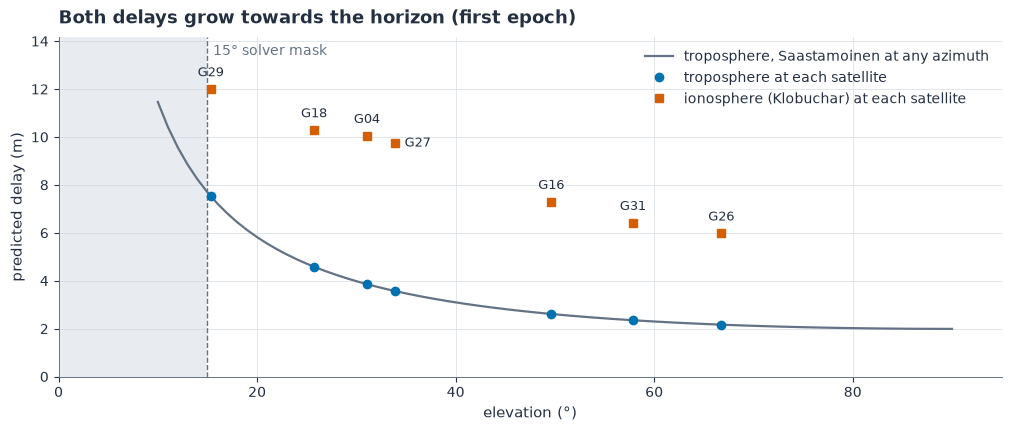

In [5]:
e = epochs[0]
lat, lon, h = geodetic(truth)
# with no coefficients in the file the solver falls back on the same default set
klob = iono or IONO_DEFAULT
rows = []
for o in e.obs:
    eph = select_ephemeris(ephs, o.prn, e.tow)
    if eph is None:
        continue
    # the same approximate light time as the sky plot
    s = satellite_state(eph, e.tow - 0.07)
    az, el = azimuth_elevation(truth, s.position)
    ion = klobuchar(klob, lat, lon, az, el, e.tow)
    rows.append((o.prn, np.degrees(el), ion, saastamoinen(lat, h, el)))
rows = np.array(rows)
for elevation in (90.0, 15.0):
    el = np.radians(elevation)
    ion, trop = klobuchar(klob, lat, lon, 0.0, el, e.tow), saastamoinen(lat, h, el)
    print(f"first epoch, azimuth 0°, elevation {elevation:g}°: "
          f"ionosphere {ion:.2f} m, troposphere {trop:.2f} m")

shown = rows[rows[:, 1] > 0]  # satellites above the horizon
print(f"first epoch, {len(shown)} satellites at {shown[:, 1].min():.1f}° to "
      f"{shown[:, 1].max():.1f}°: ionosphere {shown[:, 2].min():.2f} to "
      f"{shown[:, 2].max():.2f} m, troposphere {shown[:, 3].min():.2f} to "
      f"{shown[:, 3].max():.2f} m")
# the troposphere curve varies only the elevation
els = np.linspace(10, 90, 81)
curve = np.array([saastamoinen(lat, h, np.radians(x)) for x in els])
fig, ax = figure(figsize=(10, 4.2))
ax.axvspan(0, 15, color=BAR, alpha=0.45, linewidth=0)
ax.axvline(15, color=MUTED, linestyle="--", linewidth=1)
ax.annotate("15° solver mask", (15, 0.98), xycoords=ax.get_xaxis_transform(), xytext=(4, 0),
            textcoords="offset points", ha="left", va="top", fontsize=10, color=MUTED)
ax.plot(els, curve, color=MUTED, linestyle="-", linewidth=1.6,
        label="troposphere, Saastamoinen at any azimuth")
ax.plot(shown[:, 1], shown[:, 3], "o", color=LINES[0], ms=6, linestyle="none",
        label="troposphere at each satellite")
ax.plot(shown[:, 1], shown[:, 2], "s", color=LINES[1], ms=6, linestyle="none",
        label="ionosphere (Klobuchar) at each satellite")
# PRN labels on the ionosphere squares; within a cluster closer than 5° in elevation, the
# highest square is labelled above, the lowest to its right and any others to the left
place = {"above": ((0, 7), "center", "bottom"), "right": ((7, 0), "left", "center"),
         "left": ((-7, 0), "right", "center")}
order = shown[np.argsort(shown[:, 1])]
clusters = np.split(order, np.flatnonzero(np.diff(order[:, 1]) >= 5) + 1)
for cluster in clusters:
    ranked = cluster[np.argsort(-cluster[:, 2])]
    for k, (prn, el, ion, _) in enumerate(ranked):
        where = "above" if k == 0 else "right" if k == len(ranked) - 1 else "left"
        xy, ha, va = place[where]
        ax.annotate(f"G{int(prn):02d}", (el, ion), xytext=xy, textcoords="offset points",
                    ha=ha, va=va, fontsize=9, color=INK)
ax.legend(loc="upper right")
ax.set(xlim=(0, 95), ylim=(0, 1.18 * max(shown[:, 2:].max(), curve.max())))
ax.set_xlabel("elevation (°)")
ax.set_ylabel("predicted delay (m)")
ax.set_title("Both delays grow towards the horizon (first epoch)")
plt.show()

## 4. The solution

With satellite positions, clocks and atmospheric delays in hand, the solver fits a receiver
position and clock bias to each epoch's pseudoranges. Every epoch is solved from its own
measurements; the previous fix serves only as the starting guess, and nothing is averaged
across epochs.

The pseudorange formed in [notebook 01](01-signal-chain.ipynb) includes the receiver clock
error, and the solver estimates that clock bias together with the position. The full model
refines the sphere equation of the introduction. For satellite $s$, $P^s$ is the measured
pseudorange (m), $t_g^s$ its broadcast group delay TGD (s), $\mathrm{dt}^s$ its clock bias
including the relativistic correction (s), and $I^s$ and $T^s$ the modelled atmospheric
delays (m):

$$P^s - c\,t_g^s = \rho^s + c\,(\mathrm{dt}_r - \mathrm{dt}^s) + I^s + T^s + \eta_P^s .$$

$\eta_P^s$ is whatever the model leaves unexplained: noise, multipath and model errors. Every
term is a length in metres. A receiver clock ahead of GPS time makes every pseudorange
longer, a satellite clock ahead of GPS time makes its own pseudorange shorter, hence the
opposite signs. The broadcast clock polynomial is defined for the dual-frequency P(Y)
combination; a single-frequency L1 user corrects it by the broadcast group delay TGD, which
is what subtracting $c\,t_g^s$ from the pseudorange does.

The geometric range $\rho^s$ includes the Earth's rotation during the signal's flight, the
Sagnac correction. With satellite and receiver positions $\mathbf{x}^s = (x^s, y^s, z^s)$
and $\mathbf{x}_r = (x_r, y_r, z_r)$ in ECEF and $\Omega_E$ the Earth's rotation rate,

$$\rho^s = \lVert\mathbf{x}^s - \mathbf{x}_r\rVert + \frac{\Omega_E}{c}\,(x^s y_r - y^s x_r).$$

The satellite position belongs to the transmit time. Before iterating, the solver takes the
epoch time minus $P^s/c$, subtracts the satellite clock polynomial, and calls
`satellite_state` once per satellite; the states stay fixed while the position is fitted.

### One linear step at a time

The range is not linear in the receiver position, so the solver starts from a guess and
improves it. At the current state $\mathbf{q} = (x, y, z, c\,\mathrm{dt}_r)$ it computes,
for each satellite, the residual $v^s$ (measured minus modelled) and a row $H^s$ of the
design matrix:

$$v^s = (P^s - c\,t_g^s) - \big(\rho^s + c\,\mathrm{dt}_r - c\,\mathrm{dt}^s + I^s + T^s\big),
\qquad H^s = \big[-e^s_x,\; -e^s_y,\; -e^s_z,\; 1\big],$$

where $\mathbf{e}^s = (\mathbf{x}^s - \mathbf{x}_r)/\lVert\mathbf{x}^s - \mathbf{x}_r\rVert$
is the unit vector from receiver to satellite. Moving the receiver towards a satellite
shortens that range, hence the minus signs; raising the clock term lengthens every
predicted pseudorange equally, hence the 1. The row leaves out how the atmosphere and the
Sagnac term change with position, as both are recomputed at every new guess.

Each row and its residual are divided by $\sigma^s$, the standard deviation the model
assigns to that measurement, and the step $\delta\mathbf{q}$ is the least-squares solution
of the scaled system. With $W = \mathrm{diag}\big(1/(\sigma^s)^2\big)$:

$$\delta\mathbf{q} = \arg\min_{\mathbf{d}} \sum_s
\left(\frac{v^s - H^s\mathbf{d}}{\sigma^s}\right)^2, \qquad
(H^\mathsf{T} W H)\,\delta\mathbf{q} = H^\mathsf{T} W\,\mathbf{v}, \qquad
\mathbf{q} \leftarrow \mathbf{q} + \delta\mathbf{q}.$$

The normal equations in the middle describe the fit; the code passes the scaled rows to
`numpy.linalg.lstsq` and never forms an inverse.

The variance follows RTKLIB's single-point model: code noise that grows towards the
horizon, the satellite's broadcast accuracy, a code bias, and shares of the two atmospheric
corrections,

$$(\sigma^s)^2 = a_c^2\left(1 + \frac{1}{\sin\max(\varepsilon^s, 5^\circ)}\right) + U^2 + a_b^2
+ (f_I\, I^s)^2 + \left(\frac{a_T}{\sin\varepsilon^s + 0.1}\right)^2,$$

with $a_c = 0.3$ m of code noise, $U$ the upper bound in metres of the satellite's
broadcast accuracy index (URA), $a_b = 0.3$ m of code bias, $f_I = 0.5$ of the ionospheric
delay and $a_T = 0.3$ m of tropospheric error at the zenith. These are assumed
uncertainties, used to weight the fit and in the residual test below.

A worked case, for a satellite of URA index 0 ($U = 2.4$ m) and the ionospheric delays
printed in section 3 for the first station epoch: overhead, with $I = 5.67$ m, $\sigma$ is
about 3.8 m; at 15°, with $I = 12.88$ m, about 7.0 m. The ionosphere share is the largest
term in both, and the low satellite gets $(3.8/7.0)^2 \approx 0.29$ of the weight of the
overhead one.

### Starting, stopping and rejecting an epoch

The first epoch starts at the Earth's centre with a zero clock term. That far from the
surface, height and elevation mean nothing, so until the estimate is more than 6000 km from
the centre the solver uses unit variances and leaves out the atmosphere and the elevation
mask. Once the estimate is near the surface they switch on and are recomputed at every
guess. Each later epoch starts from the last accepted position, with the clock term reset to
zero.

The iteration stops when an update moves the state by less than $10^{-4}$ m (position
and clock term together). If that has not happened after 10 updates, the epoch gets no fix
(the loop makes at most 11 passes; the update of the last is not tested).
An epoch also gets no fix when fewer than four satellites are left above the mask, when the
geometry is degenerate, or, after convergence, when the normalised residuals fail the
chi-square check or GDOP exceeds 30. The chi-square check sums $(v^s/\sigma^s)^2$ over the
$n$ satellites and, for $n > 4$, compares the sum with RTKLIB's threshold for $n - 4$
degrees of freedom at significance 0.001.

GDOP, the geometric dilution of precision, says how strongly the satellite directions
magnify equal range errors into errors of position and clock. The solver reports the
unweighted value

$$\mathrm{GDOP} = \sqrt{\operatorname{trace}\big((H^\mathsf{T}H)^{-1}\big)} .$$

Satellites spread across the sky give a small GDOP, satellites bunched together a large
one. It includes the clock component and describes the geometry of an epoch rather than the
error of its fix.

The flowchart traces one epoch through `solve_epoch`. The loop on the left forms
residuals, solves a weighted update and rebuilds at the new estimate until the update is
below 0.1 mm; the right column checks residuals and geometry, then tries the separate
Doppler solution for velocity, which this notebook's data cannot feed.

Read more: [A standalone fix](../../docs/fundamentals/08-standalone-fix.md).

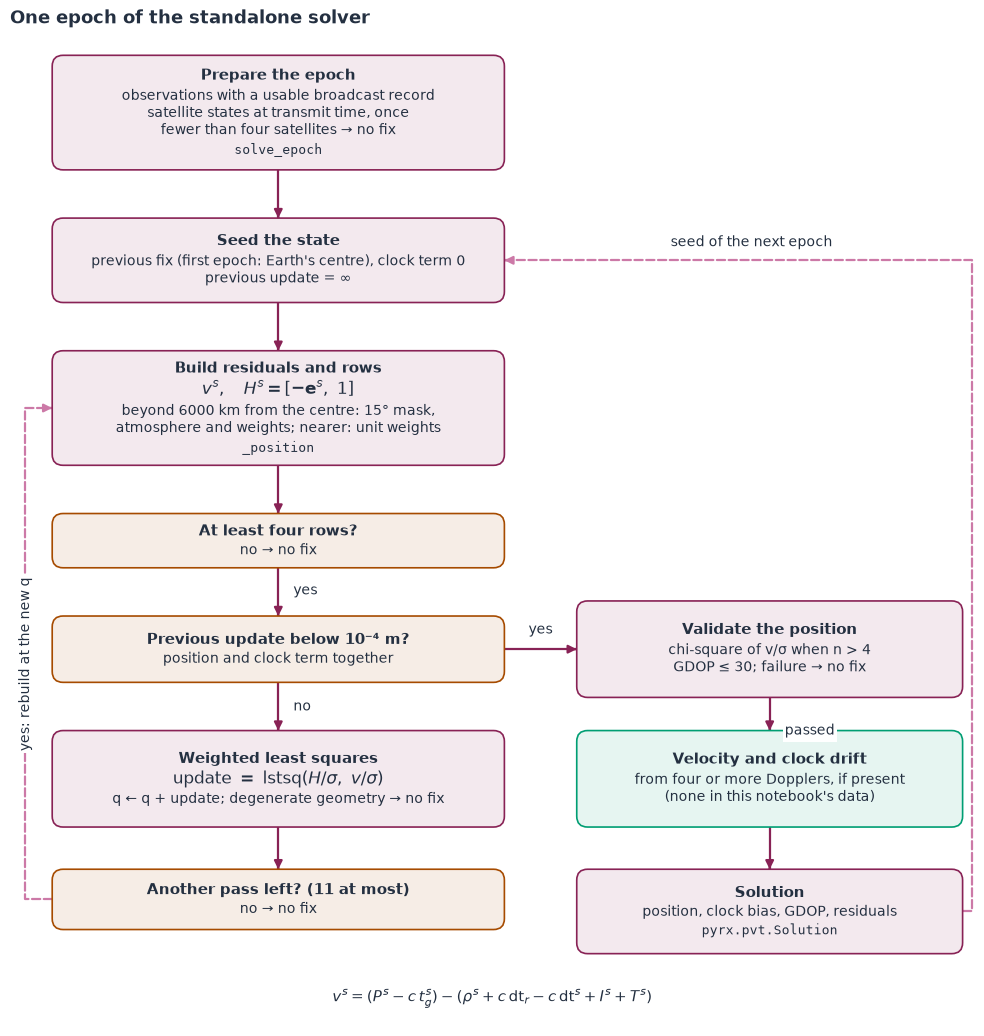

In [6]:
fig, ax = diagram_canvas(16, 16.4, "One epoch of the standalone solver")
L, LW, R, RW = 0.7, 7.5, 9.4, 6.4  # left and right columns: x and width
prep = diagram_box(
    ax, L, 14.2, LW, 1.9, "Prepare the epoch",
    "observations with a usable broadcast record\nsatellite states at transmit time, once\n"
    "fewer than four satellites → no fix",
    code="solve_epoch", role="position",
)  # fmt: skip
seed = diagram_box(
    ax, L, 12.0, LW, 1.4, "Seed the state",
    "previous fix (first epoch: Earth's centre), clock term 0\nprevious update = ∞",
    role="position",
)  # fmt: skip
build = diagram_box(
    ax, L, 9.3, LW, 1.9, "Build residuals and rows",
    "beyond 6000 km from the centre: 15° mask,\natmosphere and weights; nearer: unit weights",
    code="_position", formula=r"$v^s,\quad H^s = [-\mathbf{e}^s,\ 1]$", role="position",
)  # fmt: skip
rows4 = diagram_box(ax, L, 7.6, LW, 0.9, "At least four rows?", "no → no fix", role="highlight")
small = diagram_box(
    ax, L, 5.7, LW, 1.1, "Previous update below 10⁻⁴ m?",
    "position and clock term together", role="highlight",
)  # fmt: skip
step = diagram_box(
    ax, L, 3.3, LW, 1.6, "Weighted least squares",
    "q ← q + update; degenerate geometry → no fix",
    formula=r"update $=$ lstsq$(H/\sigma,\ v/\sigma)$", role="position",
)  # fmt: skip
again = diagram_box(
    ax, L, 1.6, LW, 1.0, "Another pass left? (11 at most)",
    "no → no fix", role="highlight",
)  # fmt: skip
check = diagram_box(
    ax, R, 5.45, RW, 1.6, "Validate the position",
    "chi-square of v/σ when n > 4\nGDOP ≤ 30; failure → no fix", role="position",
)  # fmt: skip
vel = diagram_box(
    ax, R, 3.3, RW, 1.6, "Velocity and clock drift",
    "from four or more Dopplers, if present\n(none in this notebook's data)", role="measure",
)  # fmt: skip
done = diagram_box(
    ax, R, 1.2, RW, 1.4, "Solution",
    "position, clock bias, GDOP, residuals", code="pyrx.pvt.Solution", role="position",
)  # fmt: skip
for a, b in ((prep, seed), (seed, build), (build, rows4)):
    diagram_arrow(ax, [a.bottom, b.top], role="position")
diagram_arrow(ax, [rows4.bottom, small.top], "yes", (L + LW / 2 + 0.25, 7.2), "position",
              ha="left")  # fmt: skip
diagram_arrow(ax, [small.bottom, step.top], "no", (L + LW / 2 + 0.25, 5.3), "position",
              ha="left")  # fmt: skip
diagram_arrow(ax, [step.bottom, again.top], role="position")
diagram_arrow(ax, [small.right, (R, small.right[1])], "yes", (8.8, small.right[1] + 0.3),
              "position")  # fmt: skip
diagram_arrow(ax, [check.bottom, vel.top], "passed", (R + RW / 2 + 0.25, 4.15 + 0.75),
              "position", ha="left")  # fmt: skip
diagram_arrow(ax, [vel.bottom, done.top], role="position")
diagram_arrow(ax, [again.left, (0.25, again.left[1]), (0.25, build.left[1]), build.left],
              role="control")  # fmt: skip
diagram_text(ax, 0.25, 6.0, "yes: rebuild at the new q", size=10, rotation=90,
             bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})  # fmt: skip
diagram_arrow(
    ax, [done.right, (15.95, done.right[1]), (15.95, seed.right[1]), seed.right],
    "seed of the next epoch", (12.3, seed.right[1] + 0.3), "control",
)  # fmt: skip
diagram_text(
    ax, 8.0, 0.45,
    r"$v^s = (P^s - c\,t_g^s) - (\rho^s + c\,\mathrm{dt}_r - c\,\mathrm{dt}^s + I^s + T^s)$",
    size=11,
)  # fmt: skip
plt.show()

In [7]:
sols = solve(epochs, ephs, iono, 15.0)
# east, north, up of each fix about the reference position
err = enu(np.array([s.position for s in sols]), truth)
d3 = np.linalg.norm(err, axis=1)  # the ENU rotation keeps lengths: the 3-D offset
t_sol = elapsed_minutes(sols, epochs[0])
t_obs = elapsed_minutes(epochs, epochs[0])
print(f"{len(sols)} of {len(epochs)} epochs fixed; 3-D offset mean {d3.mean():.2f} m, "
      f"95th percentile {np.percentile(d3, 95):.2f} m, max {d3.max():.2f} m")
print(f"mean offset E {err[:, 0].mean():+.2f} m, N {err[:, 1].mean():+.2f} m, "
      f"U {err[:, 2].mean():+.2f} m")
clock_us = np.array([s.clock_bias for s in sols]) * 1e6  # clock_bias is in seconds
print(f"receiver clock bias {clock_us.min():.3f} to {clock_us.max():.3f} µs")
gdop = np.array([s.gdop for s in sols])
used = np.array([len(s.prns) for s in sols])
print(f"GDOP {gdop.min():.2f} to {gdop.max():.2f}; {used.min()} to {used.max()} satellites used")
# the missing timestamps say which epochs failed, not which check failed them
fixed = {(s.week, s.tow) for s in sols}
missing = [i for i, e in enumerate(epochs) if (e.week, e.tow) not in fixed]
for i in missing:
    e = epochs[i]
    print(f"no fix at {gps_datetime(e.week, e.tow):%H:%M:%S} GPST ({t_obs[i]:.1f} min)")

360 of 361 epochs fixed; 3-D offset mean 8.11 m, 95th percentile 9.81 m, max 12.33 m
mean offset E +0.54 m, N +0.88 m, U -8.01 m
receiver clock bias 3.465 to 3.490 µs
GDOP 1.99 to 4.26; 5 to 8 satellites used
no fix at 10:16:30 GPST (136.5 min)


### Reading the solution

The figure resolves each fix's offset from the reference position into local east, north
and up (ENU) components, with the satellite geometry and the receiver clock below on the
same time axis. On the committed USUD window the mean offsets are E +0.54 m, N +0.88 m and
U −8.01 m, and the 3-D offset averages 8.11 m. The dashed circle on the right holds 95 % of
the horizontal offsets.

Height is often the weakest coordinate of a standalone fix: every satellite is above the
horizon, and a change of height looks partly like a change of the clock term. Near the
receiver, a height change $\delta u$ changes the range to a satellite at elevation
$\varepsilon^s$ by about $-\sin\varepsilon^s\,\delta u$, while a change of the clock term
adds the same amount to every range. A model that removes too much delay from the low
satellites relative to the high ones can therefore push the fitted height down once the
clock has taken up the common part. That gives the sign such an error would produce. Which
error is behind the −8.01 m here, ionosphere, troposphere or the reference coordinates,
the notebook cannot tell; the header's 3.5 cm antenna offset, which the solve does not
apply, is far too small to matter. The synthetic observations contain exactly the models the
solver removes, plus 0.3 m of noise, so they show no such bias.

On the station data GDOP stays between 2.0 and 4.3 with 5 to 8 satellites in the fix,
fewer than are observed because of the mask and the record checks; its jumps come where a
satellite enters or leaves the fix. The orange triangle on the count strip marks the one
station epoch without a fix, at 10:16:30 GPST, 136.5 min into the window. `solve` returns
no reason for a missing fix; with enough satellites in view, the checks that can reject an
epoch are convergence, the chi-square check and the GDOP limit.

The receiver clock is the fourth unknown. On the committed window it drifts slowly from
3.465 to 3.490 µs. The
synthetic clock starts at 100 µs and grows linearly by construction. With 1 µs worth about
300 m of common range, even a large clock bias is estimated alongside the position without
disturbing it.

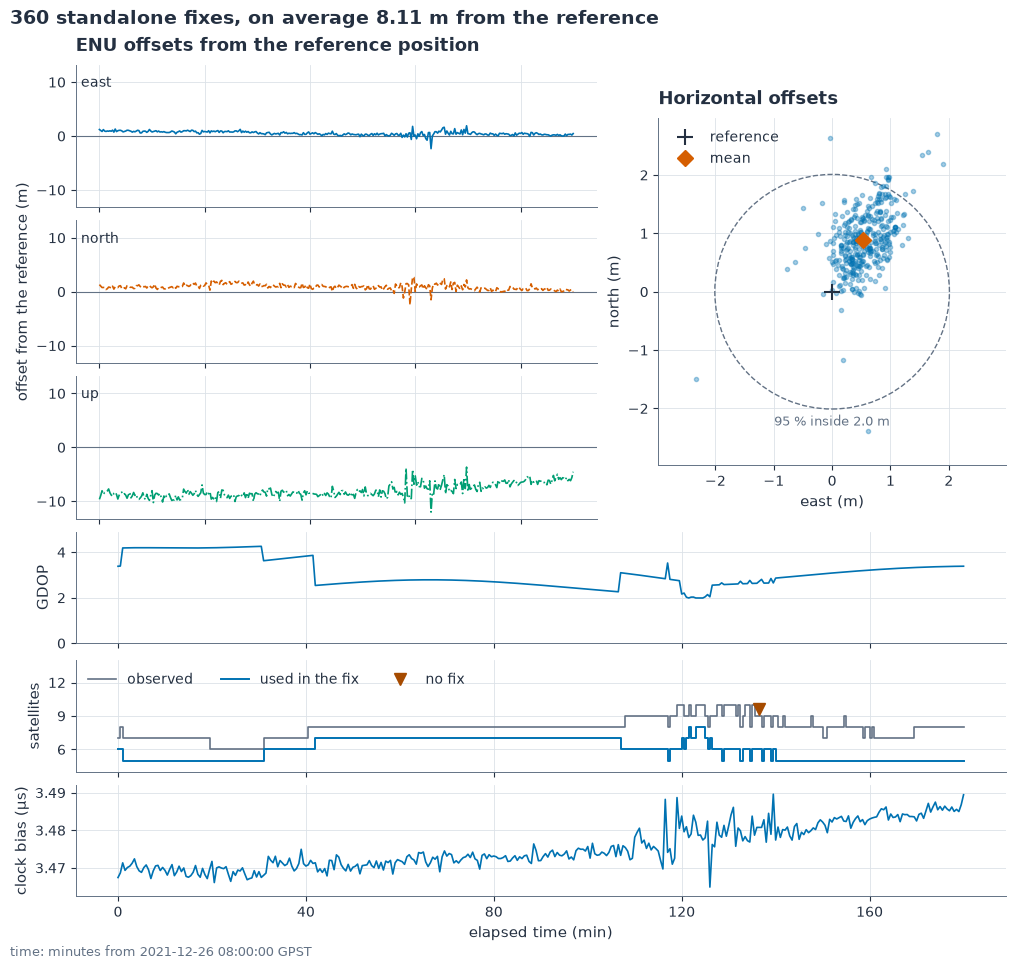

In [8]:
fig, _ = figure(figsize=(10, 9.4))
fig.clear()
axd = fig.subplot_mosaic(
    [["east", "horiz"], ["north", "horiz"], ["up", "horiz"],
     ["gdop", "gdop"], ["sats", "sats"], ["clock", "clock"]],
    width_ratios=[3, 2], height_ratios=[1.15, 1.15, 1.15, 0.9, 0.9, 0.9],
)  # fmt: skip
lim = 1.1 * np.abs(err).max()
for j, (name, dash) in enumerate(zip(("east", "north", "up"), ("-", "--", "-."))):
    ax = axd[name]
    ax.sharex(axd["clock"])
    ax.axhline(0, color=MUTED, linewidth=0.8)
    ax.plot(t_sol, err[:, j], color=LINES[j], linestyle=dash, linewidth=1.2)
    ax.set_ylim(-lim, lim)
    ax.text(0.01, 0.92, name, transform=ax.transAxes, va="top", fontsize=10, color=INK)
    ax.tick_params(labelbottom=False)
axd["north"].set_ylabel("offset from the reference (m)")
axd["east"].set_title("ENU offsets from the reference position")

ax = axd["horiz"]
radius = np.percentile(np.linalg.norm(err[:, :2], axis=1), 95)
hlim = max(1.0, 1.1 * np.abs(err[:, :2]).max(), 1.1 * radius)
ax.plot(err[:, 0], err[:, 1], "o", color=LINES[0], ms=3, alpha=0.35, linestyle="none")
ax.plot(0, 0, "+", color=INK, ms=12, mew=1.5, linestyle="none", label="reference")
ax.plot(*err[:, :2].mean(axis=0), "D", color=LINES[1], ms=8, linestyle="none", label="mean")
ax.add_patch(plt.Circle((0, 0), radius, fill=False, color=MUTED, linestyle="--"))
ax.annotate(f"95 % inside {radius:.1f} m", (0, -radius), xytext=(0, -4),
            textcoords="offset points", ha="center", va="top", fontsize=9, color=MUTED)
ax.set(xlim=(-hlim, hlim), ylim=(-hlim, hlim), aspect="equal")
ax.set_xlabel("east (m)")
ax.set_ylabel("north (m)")
ax.legend(loc="upper left")
ax.set_title("Horizontal offsets")

ax = axd["gdop"]
ax.sharex(axd["clock"])
ax.plot(t_sol, gdop, color=LINES[0], linestyle="-", linewidth=1.2)
ax.set_ylim(0, 1.15 * gdop.max())
ax.set_ylabel("GDOP")
ax.tick_params(labelbottom=False)

ax = axd["sats"]
ax.sharex(axd["clock"])
ax.step(t_obs, observed, where="post", color=MUTED, linestyle="-", linewidth=1.2,
        label="observed")
ax.step(t_sol, used, where="post", color=LINES[0], linestyle="-", linewidth=1.4,
        label="used in the fix")
if missing:
    ax.plot(t_obs[missing], observed[missing] + 0.6, "v", color=HIGHLIGHT, ms=8,
            linestyle="none", label="no fix")
ax.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
ax.set_ylim(used.min() - 1, observed.max() + 4)
ax.set_ylabel("satellites")
ax.legend(loc="upper left", ncols=3)
ax.tick_params(labelbottom=False)

ax = axd["clock"]
ax.plot(t_sol, clock_us, color=LINES[0], linestyle="-", linewidth=1.2)
span = clock_us.max() - clock_us.min()
ax.set_ylim(clock_us.min() - 0.1 * span, clock_us.max() + 0.1 * span)
ax.set_ylabel("clock bias (µs)")
ax.set_xlabel("elapsed time (min)")
ax.xaxis.set_major_locator(MaxNLocator(5))
fig.suptitle(f"{len(sols)} standalone fixes, on average {d3.mean():.2f} m from the reference",
             x=0.0, ha="left")
figure_note(fig, time_note(epochs[0], src is None))
plt.show()

### What remains in the ranges

After the fit, each satellite used still has a pseudorange residual: the corrected
observation minus the pseudorange predicted at the final state. A positive residual means
the observation is longer than the model predicts. The histogram pools the residuals, in
metres, from every accepted epoch, one entry per satellite per epoch, so epochs with more
satellites contribute more entries. The count axis is logarithmic so that the rare large
residuals stay visible next to the many small ones.

The title gives the unweighted root mean square of all of them. On the committed USUD
window it is 0.63 m over 2159 residuals, the middle 95 % lie between −0.95 and +1.11 m, and
a single residual reaches about −11 m, all against a mean 3-D position offset of 8.11 m.
The fit absorbs part of any error that the satellites share into the position and the
clock, so small residuals can sit beside a large position offset. Their sub-metre spread
is typical of code measurements. The solver's chi-square check works on the residuals
divided by their assumed standard deviations, whereas this plot shows plain metres.

Synthetic data: the RMS is 0.15 m although 0.3 m of noise went in. With six satellites and
four unknowns only two degrees of freedom are left (one once a satellite drops below the
mask), so the fit takes up most of the noise: $\sqrt{2/6}\times 0.3$ m is about 0.17 m and
$\sqrt{1/5}\times 0.3$ m about 0.13 m.

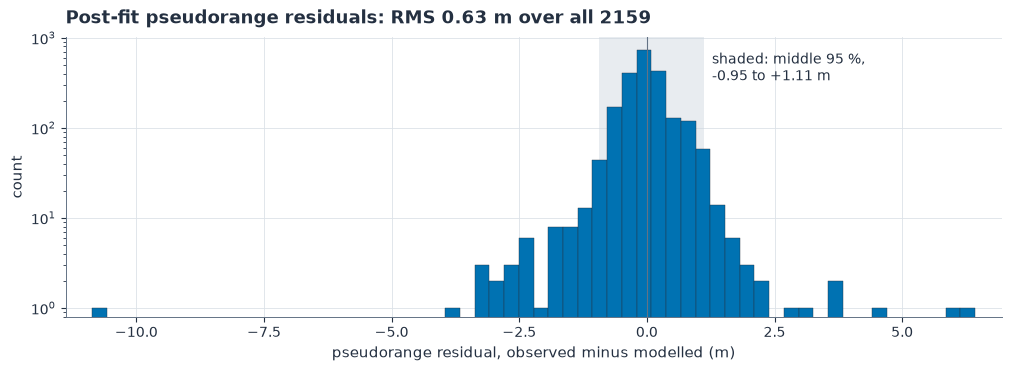

In [9]:
# unscaled post-fit residuals of the satellites used, pooled over all accepted epochs
res = np.concatenate([s.residuals for s in sols])
lo, hi = np.percentile(res, [2.5, 97.5])
fig, ax = figure(figsize=(10, 3.6))
ax.axvspan(lo, hi, color=BAR, alpha=0.45, linewidth=0)
ax.hist(res, bins=60, color=BAR_DETECTED, edgecolor=INK, linewidth=0.3)
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(bottom=0.8)
ax.annotate(f"shaded: middle 95 %,\n{lo:+.2f} to {hi:+.2f} m", (hi, 0.95),
            xycoords=ax.get_xaxis_transform(), xytext=(6, 0), textcoords="offset points",
            ha="left", va="top", fontsize=10, color=INK)
span = res.max() - res.min()
ax.set_xlim(min(res.min(), 0) - 0.03 * span, max(res.max(), 0) + 0.03 * span)
ax.set_xlabel("pseudorange residual, observed minus modelled (m)")
ax.set_ylabel("count")
ax.set_title(f"Post-fit pseudorange residuals: RMS {np.sqrt(np.mean(res**2)):.2f} m "
             f"over all {len(res)}")
plt.show()

## 5. Comparison with RTKLIB

RTKLIB is an independent open-source GNSS positioning package; its `rnx2rtkp` program
computes positions from RINEX files. Here it solves the same USUD observation and
navigation files in single-point mode with the settings of the `pyrx` run: GPS only, a 15°
elevation mask, broadcast ephemerides and Klobuchar coefficients, and the Saastamoinen
troposphere. The code joins the two sets of fixes by GPS week and time of week and compares
them at the epochs both programs solved, about the same reference position.

Both columns plot RTKLIB minus `pyrx` in millimetres, east, north and up. The left column
zooms to ±1 mm and marks the points beyond it with triangles at the edge; the right column
is linear within ±1 mm and logarithmic outside, so it keeps every difference on the plot.
Each marked epoch is labelled in the right-hand panel of its largest component.

On the committed 360 common epochs the mean absolute differences are 0.4 mm east, 0.1 mm
north and 0.7 mm up, while the medians are about 0.02 mm in all three. The gap between the
two statistics comes from the two epochs marked by dashed lines, 60 and 180 min into the
window (09:00 and 11:00 GPST). Each falls exactly midway between the reference times `toe`
of two records of one satellite, and the two programs pick different records. At 60 min
the up difference is −159.7 mm; at 180 min east is −113.5 mm and up −77.3 mm. Spread over
360 epochs, (159.7 + 77.3)/360 ≈ 0.66 mm, most of the mean up difference.

Close agreement shows that the two programs implement the same models and the same solve.
It does not show how far either is from the true position: they share the observations, the
models and the reference coordinates, and so share any bias those carry, including the
metres of height offset in section 4.

Synthetic data: this comparison is skipped because there is no external solution for the
generated observations. With real data it also needs `rnx2rtkp` on `PATH`.

360 common epochs; RTKLIB minus pyrx, mean absolute difference: E 0.4 mm, N 0.1 mm, U 0.7 mm
median absolute difference: E 0.022 mm, N 0.022 mm, U 0.019 mm (both statistics include every epoch)
60.0 min: E +20.4, N -18.3, U -159.7 mm
180.0 min: E -113.5, N -21.5, U -77.3 mm


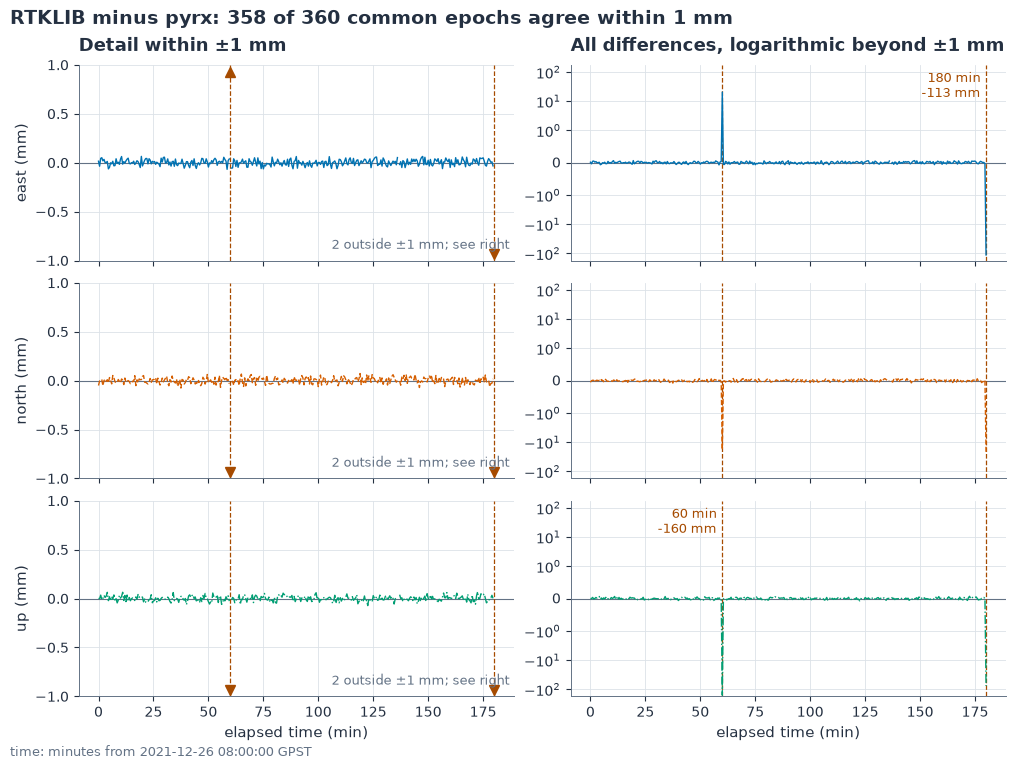

In [10]:
def broken(t, y, gap):
    # NaN between epochs further apart than `gap`, so lines join only consecutive epochs
    cut = np.flatnonzero(np.diff(t) > gap) + 1
    return np.insert(t, cut, np.nan), np.insert(y, cut, np.nan)


ref = None if src is None else rnx2rtkp_single(src.usud_obs, src.usud_nav, out, PVT_SPAN)
if src is None:
    print("Synthetic data: comparison skipped (no external reference data).")
elif ref is None:
    print("Comparison skipped.")
else:
    keys = [(s.week, round(s.tow, 1)) for s in sols]
    # only epochs both programs solved, about the same ENU origin
    both = [(i, ref[k]) for i, k in enumerate(keys) if k in ref]
    idx = np.array([i for i, _ in both])
    ref_err = enu(np.array([xyz for _, xyz in both]), truth)
    diff_mm = (ref_err - err[idx]) * 1e3  # RTKLIB minus pyrx
    mae, med = np.abs(diff_mm).mean(axis=0), np.median(np.abs(diff_mm), axis=0)
    print(f"{len(both)} common epochs; RTKLIB minus pyrx, mean absolute difference: "
          f"E {mae[0]:.1f} mm, N {mae[1]:.1f} mm, U {mae[2]:.1f} mm")
    print(f"median absolute difference: E {med[0]:.3f} mm, N {med[1]:.3f} mm, "
          f"U {med[2]:.3f} mm (both statistics include every epoch)")
    tc = t_sol[idx]
    big = np.flatnonzero(np.abs(diff_mm).max(axis=1) > 1.0)
    for i in big:
        print(f"{tc[i]:.1f} min: E {diff_mm[i, 0]:+.1f}, N {diff_mm[i, 1]:+.1f}, "
              f"U {diff_mm[i, 2]:+.1f} mm")
    outer = max(1.0, 1.1 * np.abs(diff_mm).max())
    gap = 1.5 * np.median(np.diff(tc))
    fig, axes = figure(3, 2, figsize=(10, 7.4), sharex=True)
    for j, (name, dash) in enumerate(zip(("east", "north", "up"), ("-", "--", "-."))):
        d = diff_mm[:, j]
        left, right = axes[j]
        for ax in (left, right):
            ax.axhline(0, color=MUTED, linewidth=0.8)
            for i in big:
                ax.axvline(tc[i], color=HIGHLIGHT, linestyle="--", linewidth=0.9)
        inside = np.abs(d) <= 1.0
        left.plot(*broken(tc, np.where(inside, d, np.nan), gap), dash, color=LINES[j],
                  linewidth=1.0)
        for sign, mark in ((1, "^"), (-1, "v")):
            over = sign * d > 1.0
            left.plot(tc[over], np.full(over.sum(), sign * 0.93), mark, color=HIGHLIGHT, ms=7,
                      linestyle="none")
        if (~inside).any():
            left.text(0.99, 0.06, f"{(~inside).sum()} outside ±1 mm; see right",
                      transform=left.transAxes, ha="right", fontsize=9, color=MUTED)
        left.set_ylim(-1, 1)
        left.set_ylabel(f"{name} (mm)")
        right.plot(*broken(tc, d, gap), dash, color=LINES[j], linewidth=1.0)
        right.set_yscale("symlog", linthresh=1.0, linscale=1.0)
        right.set_ylim(-outer, outer)
    for i in big:
        k = int(np.argmax(np.abs(diff_mm[i])))  # the largest component, in its own panel
        axes[k, 1].annotate(f"{tc[i]:.0f} min\n{diff_mm[i, k]:+.0f} mm",
                            (tc[i], 0.97), xycoords=axes[k, 1].get_xaxis_transform(),
                            xytext=(-4, 0), textcoords="offset points", ha="right", va="top",
                            fontsize=9, color=HIGHLIGHT)
    axes[0, 0].set_title("Detail within ±1 mm")
    axes[0, 1].set_title("All differences, logarithmic beyond ±1 mm")
    for ax in axes[2]:
        ax.set_xlabel("elapsed time (min)")
    fig.suptitle(f"RTKLIB minus pyrx: {int((np.abs(diff_mm).max(axis=1) <= 1).sum())} of "
                 f"{len(both)} common epochs agree within 1 mm", x=0.0, ha="left")
    figure_note(fig, time_note(epochs[0], False))
    plt.show()

## From code positioning to carrier phase

The position came from pseudoranges, broadcast orbits and clocks, atmospheric predictions,
and a weighted fit of three coordinates and a clock term at each epoch, with the previous
fix as the starting guess. On the committed USUD window 360 of 361 epochs have a fix,
8.11 m from the reference position on average, and RTKLIB's fixes agree with them within a
millimetre at 358 of the 360 common epochs. Synthetic data: the measurements come from
the package's own models with code noise and a drifting clock, so the fixes land close to
the generating position.

Metres are what pseudoranges give on their own. [Notebook 03](03-rtk.ipynb) moves to a pair
of stations about 11 m apart, MATE and MAT1 in Matera, Italy, and uses carrier phase as well
as pseudorange. Differencing the two receivers' measurements cancels most of the errors
they share, and resolving the unknown whole numbers of carrier cycles makes much finer
relative positioning possible. Its relative solution starts each epoch from the
single-point solver used here.